## qualidade dos dados

In [ ]:
import pandas as pd
df = pd.read_csv("raw/merged_1sel_full.csv", delimiter=';')
df = df[df['Período']>=2016]
df = df.drop(columns=['Unnamed: 0'])

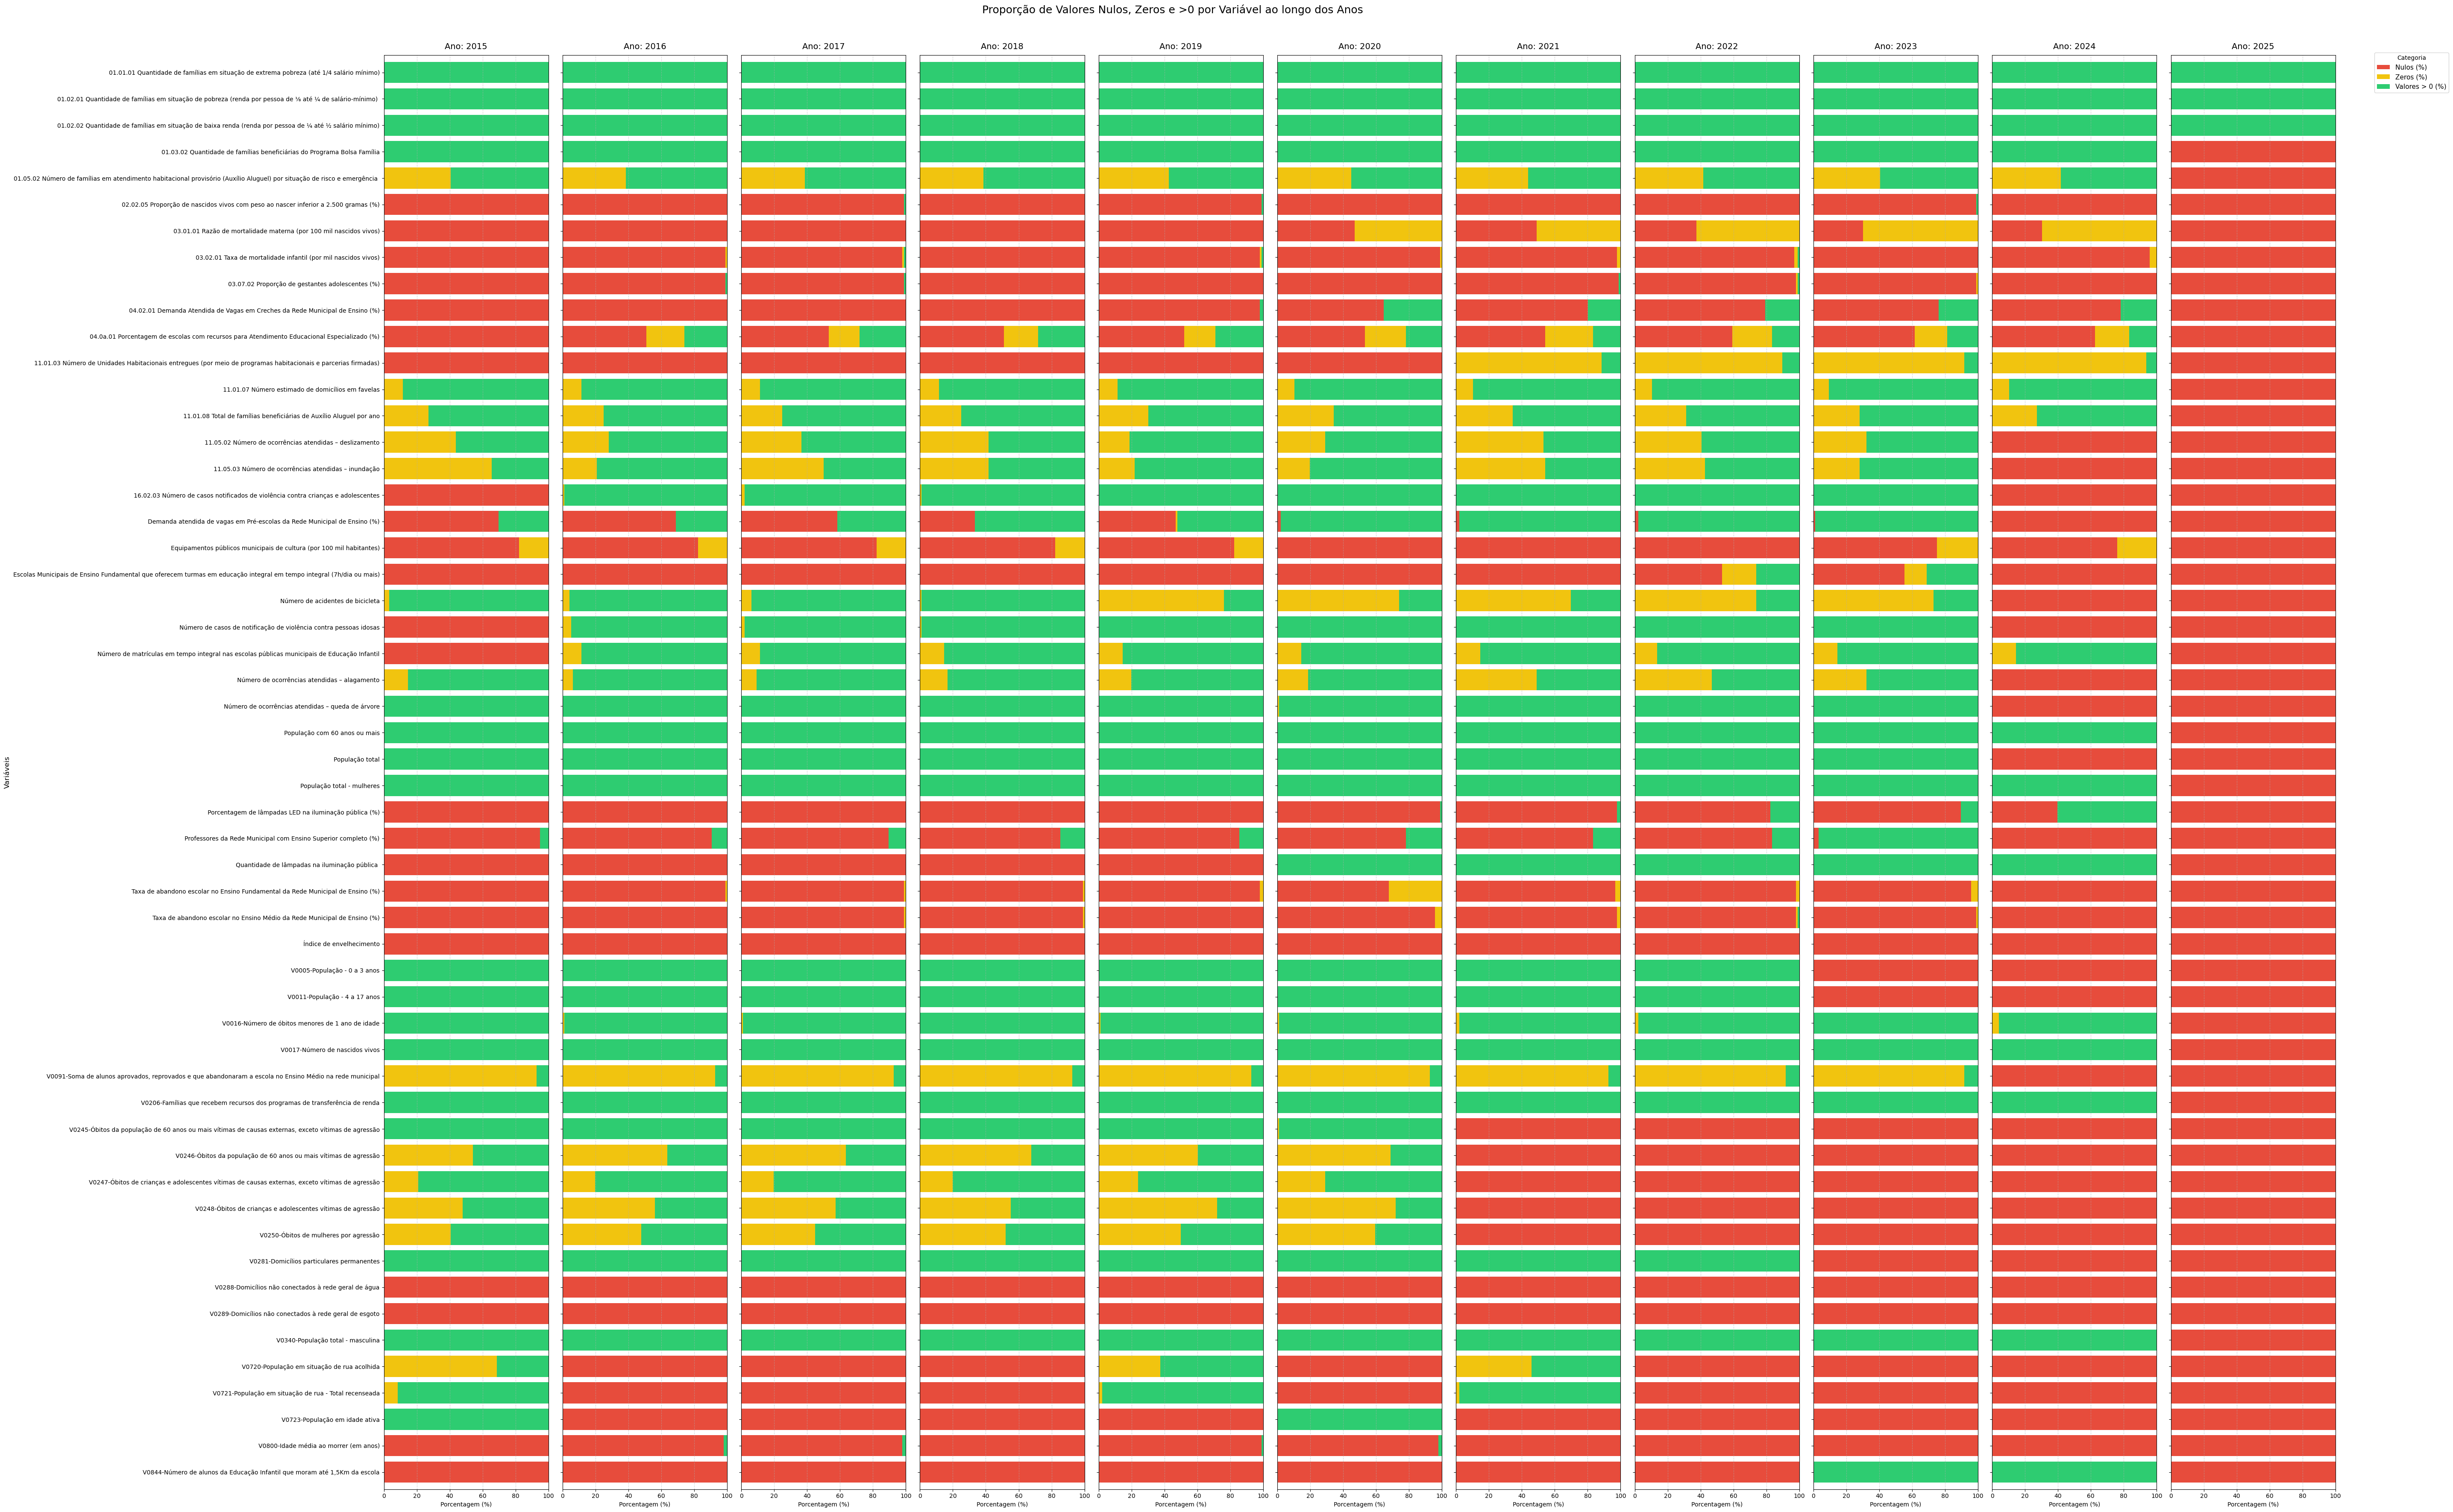

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Identifica os anos únicos disponíveis no dataframe e os ordena
anos = sorted(df['Período'].dropna().unique())
num_anos = len(anos)

# Identifica apenas as colunas de variáveis (excluindo 'Período' e 'Distrito')
cols_variaveis = [col for col in df.columns if col not in ['Período', 'Distrito']]

# 2. Cria a figura com subplots (1 linha, múltiplas colunas)
# sharey=True garante que os rótulos do eixo Y (nomes das variáveis) fiquem apenas no primeiro gráfico
fig, axes = plt.subplots(nrows=1, ncols=num_anos, figsize=(5 * num_anos, 35), sharey=True)

# Garante que axes seja iterável caso haja apenas 1 ano na base
if num_anos == 1:
    axes = [axes]

# 3. Loop para calcular proporções e plotar cada ano em seu respectivo eixo (ax)
for ax, ano in zip(axes, anos):
    # Filtra os dados especificamente para o ano do loop
    df_ano = df[df['Período'] == ano]
    
    dados_proporcao = []

    for col in cols_variaveis:
        # Converte os dados para numérico
        s = pd.to_numeric(df_ano[col], errors='coerce')
        total = len(s)

        # Trata caso não haja registros para o ano (evita erro de divisão por zero)
        if total == 0:
            perc_nulos, perc_zeros, perc_maiores_zero = 100, 0, 0
        else:
            perc_nulos = (s.isna().sum() / total) * 100
            perc_zeros = ((s == 0).sum() / total) * 100
            perc_maiores_zero = ((s > 0).sum() / total) * 100

        dados_proporcao.append({
            'Variável': col,
            'Nulos (%)': perc_nulos,
            'Zeros (%)': perc_zeros,
            'Valores > 0 (%)': perc_maiores_zero
        })

    df_prop = pd.DataFrame(dados_proporcao).set_index('Variável')

    # Plotagem das barras no subplot atual (ax)
    df_prop[['Nulos (%)', 'Zeros (%)', 'Valores > 0 (%)']].plot(
        kind='barh',
        stacked=True,
        ax=ax,
        color=['#e74c3c', '#f1c40f', '#2ecc71'],  # Vermelho (Nulos), Amarelo (0s), Verde (>0s)
        width=0.8,
        legend=False # Desativamos a legenda individual para colocar apenas uma global depois
    )

    # Ajustes estéticos individuais de cada subplot
    ax.set_title(f'Ano: {int(ano)}', fontsize=14, pad=10)
    ax.set_xlabel('Porcentagem (%)', fontsize=10)
    ax.set_xlim(0, 100)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    
    # Mantém o rótulo do eixo Y apenas no primeiro gráfico
    if ax == axes[0]:
        ax.set_ylabel('Variáveis', fontsize=12)
    else:
        ax.set_ylabel('')

# Inverte o eixo Y apenas do primeiro eixo (afeta todos devido ao sharey=True)
axes[0].invert_yaxis()

# Adiciona um título geral para a imagem completa
fig.suptitle('Proporção de Valores Nulos, Zeros e >0 por Variável ao longo dos Anos', fontsize=18, y=1.01)

# Pega os handles do último gráfico para criar uma legenda única do lado direito
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, title='Categoria', bbox_to_anchor=(1.01, 0.98), loc='upper left', fontsize=11)

plt.tight_layout()

# 1. Salva a imagem em alta resolução
plt.savefig(
    'proporcao_variaveis_sel1_por_ano.png', # Nome e extensão do arquivo
    dpi=300,                            # 300 DPI garante qualidade de impressão/relatório
    bbox_inches='tight',                # Evita que legendas ou títulos na borda sejam cortados
    pad_inches=0.2,                     # Adiciona uma margem de segurança ao redor do gráfico
    facecolor='white',                  # Garante fundo branco (evita fundo transparente)
    transparent=False
)

plt.show()

## correlação

In [ ]:
import pandas as pd
df = pd.read_csv("raw/merged_2sel_full.csv", delimiter=';')
#df = df[df['Período']>=2016]
df = df.drop(columns=['Unnamed: 0'])

KeyError: 'Período'